# Model, SHAP, and risk tiers

Logistic regression as a baseline, then XGBoost with class weighting. SHAP explains the scores. Every customer is written back to SQLite with a risk tier, and a high-risk retention list is pulled in SQL.

## Prepare the data

`city` and `branch_code` are dropped on purpose: they are high-cardinality codes that mostly add noise. `customer_id`, `last_transaction`, `rfm_segment`, and the target `churn` are also held out of `X`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sqlite3
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

root = Path.cwd()
if not (root / "churn.db").exists() and (root.parent / "churn.db").exists():
    os.chdir(root.parent)

Path("data/processed").mkdir(parents=True, exist_ok=True)
Path("outputs").mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect("churn.db")
df = pd.read_sql("SELECT * FROM features", conn)

drop_cols = ["customer_id", "last_transaction", "churn", "city", "branch_code", "rfm_segment"]
X = df.drop(columns=drop_cols)
X["gender"] = X["gender"].fillna("Unknown")
X["occupation"] = X["occupation"].fillna("Unknown")
X["dependents"] = X["dependents"].fillna(0)
X = pd.get_dummies(X, columns=["gender", "occupation"], drop_first=True)
y = df["churn"]

print(X.shape, y.mean().round(4))
X.head()

Matplotlib is building the font cache; this may take a moment.


(28382, 29) 0.1853


,vintage,age,dependents,customer_nw_category,current_balance,previous_month_end_balance,average_monthly_balance_prevQ,average_monthly_balance_prevQ2,current_month_credit,previous_month_credit,...,debit_trend,r_score,m_score,gender_Male,gender_Unknown,occupation_company,occupation_retired,occupation_salaried,occupation_self_employed,occupation_student
0,2335,40,0.0,3,3328.77,3326.03,3325.71,2335.07,0.01,0.01,...,1.0,1,1,False,False,False,False,False,True,False
1,1996,59,0.0,2,3099.14,3011.65,3030.91,3044.81,0.01,0.01,...,1.0,1,1,True,False,False,False,False,True,False
2,1531,49,0.0,2,2077.91,1942.20,1931.98,1567.55,0.01,0.01,...,1.0,1,1,False,False,False,False,False,True,False
3,1967,49,0.0,2,1732.34,1732.34,1732.34,2422.04,0.01,0.01,...,1.0,1,1,True,False,False,False,True,False,False
4,2243,73,0.0,2,6133.74,6131.31,6129.91,6225.67,0.01,0.01,...,1.0,1,1,True,False,False,False,False,True,False


In [2]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("train churn rate", y_tr.mean().round(4), "test churn rate", y_te.mean().round(4))

train churn rate 0.1853 test churn rate 0.1853


## Logistic regression baseline

Scale features and fill remaining nulls with 0 — logistic regression cannot handle missing values.

In [3]:
X_tr_lr = X_tr.fillna(0)
X_te_lr = X_te.fillna(0)

lr = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "clf",
            LogisticRegression(
                max_iter=2000, class_weight="balanced", random_state=42
            ),
        ),
    ]
)
lr.fit(X_tr_lr, y_tr)
lr_proba = lr.predict_proba(X_te_lr)[:, 1]
lr_pred = (lr_proba > 0.5).astype(int)

print("AUC", round(roc_auc_score(y_te, lr_proba), 3))
print(classification_report(y_te, lr_pred, digits=3))

AUC 0.754
              precision    recall  f1-score   support

           0      0.908     0.696     0.788      4625
           1      0.341     0.691     0.457      1052

    accuracy                          0.695      5677
   macro avg      0.625     0.694     0.622      5677
weighted avg      0.803     0.695     0.727      5677



## XGBoost

`scale_pos_weight` tells XGBoost to pay more attention to churners since they are the minority. Nulls are left as-is because trees handle them natively.

In [4]:
model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=(y_tr == 0).sum() / (y_tr == 1).sum(),
    eval_metric="auc",
    random_state=42,
)
model.fit(X_tr, y_tr)
proba = model.predict_proba(X_te)[:, 1]
print("AUC", round(roc_auc_score(y_te, proba), 3))

AUC 0.839


### Threshold sweep

Pick the cutoff that keeps churn recall high without flooding the list with false alarms.

In [5]:
for t in [0.3, 0.4, 0.5, 0.6]:
    pred = (proba > t).astype(int)
    print(t, accuracy_score(y_te, pred), roc_auc_score(y_te, proba))
    print(classification_report(y_te, pred, digits=3))

0.3 0.7172802536550995 0.8391020450107902
              precision    recall  f1-score   support

           0      0.943     0.695     0.800      4625
           1      0.378     0.816     0.517      1052

    accuracy                          0.717      5677
   macro avg      0.661     0.755     0.658      5677
weighted avg      0.838     0.717     0.748      5677

0.4 0.7861546591509601 0.8391020450107902
              precision    recall  f1-score   support

           0      0.934     0.794     0.858      4625
           1      0.454     0.752     0.566      1052

    accuracy                          0.786      5677
   macro avg      0.694     0.773     0.712      5677
weighted avg      0.845     0.786     0.804      5677

0.5 0.8247313722036287 0.8391020450107902
              precision    recall  f1-score   support

           0      0.921     0.859     0.889      4625
           1      0.521     0.675     0.588      1052

    accuracy                          0.825      5677
  

In [6]:
CHOSEN_THRESHOLD = 0.4
xgb_pred = (proba > CHOSEN_THRESHOLD).astype(int)

results = pd.DataFrame(
    [
        {
            "model": "Logistic regression",
            "threshold": 0.5,
            "accuracy": accuracy_score(y_te, lr_pred),
            "precision": precision_score(y_te, lr_pred),
            "recall": recall_score(y_te, lr_pred),
            "AUC": roc_auc_score(y_te, lr_proba),
        },
        {
            "model": "XGBoost",
            "threshold": CHOSEN_THRESHOLD,
            "accuracy": accuracy_score(y_te, xgb_pred),
            "precision": precision_score(y_te, xgb_pred),
            "recall": recall_score(y_te, xgb_pred),
            "AUC": roc_auc_score(y_te, proba),
        },
    ]
)
results.round(3)

,model,threshold,accuracy,precision,recall,AUC
0,Logistic regression,0.5,0.695,0.341,0.691,0.754
1,XGBoost,0.4,0.786,0.454,0.752,0.839


0.4 is the operating point: better churn recall than 0.5/0.6, fewer false alarms than 0.3. Change `CHOSEN_THRESHOLD` above if the sweep suggests otherwise.

## Explain the model with SHAP

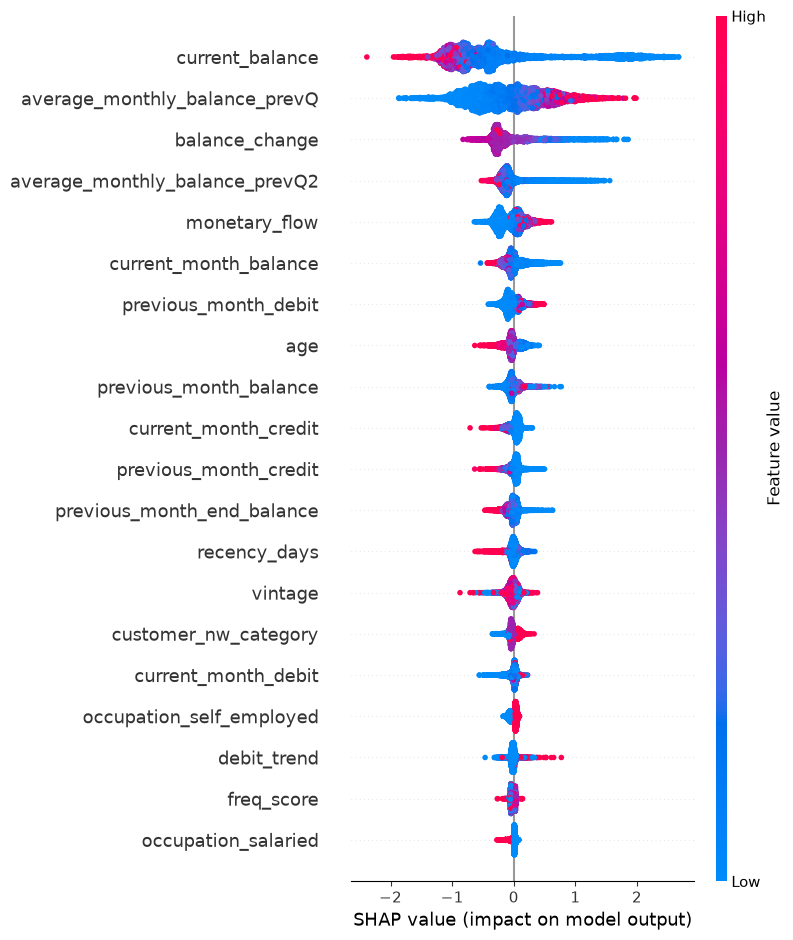

In [7]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_te)
shap.summary_plot(shap_values, X_te, show=False)
plt.savefig("outputs/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
imp = pd.DataFrame(
    {"feature": X_te.columns, "importance": np.abs(shap_values).mean(axis=0)}
)
imp = imp.sort_values("importance", ascending=False)
imp.to_csv("data/processed/drivers.csv", index=False)
imp.head(10)

,feature,importance
4,current_balance,0.801555
6,average_monthly_balance_prevQ,0.488610
18,balance_change,0.292602
7,average_monthly_balance_prevQ2,0.193497
17,monetary_flow,0.162911
12,current_month_balance,0.118965
11,previous_month_debit,0.098704
1,age,0.094357
13,previous_month_balance,0.075248
8,current_month_credit,0.069405


In [9]:
stories = {
    "current_balance": "Low remaining balances leave little reason to stay; high-balance customers are stickier and more valuable to save.",
    "current_month_balance": "This month's running balance is a near-real-time view of whether money is still sitting in the account.",
    "previous_month_end_balance": "Last month's ending balance is a lagging wealth signal; a drop from here often precedes churn.",
    "average_monthly_balance_prevQ": "Sustained low balances over the last quarter flag accounts that have already quietly emptied.",
    "average_monthly_balance_prevQ2": "Even older average balances help separate chronically thin accounts from a one-month dip.",
    "previous_month_balance": "Balance last month complements current_balance as a short-horizon activity check.",
    "balance_change": "A sharp month-over-month drawdown is often the last step before the customer leaves.",
    "recency_days": "Days since last transaction: the longer the silence, the more likely the relationship is already over.",
    "r_score": "RFM recency bucket. Low scores (stale activity) concentrate churn.",
    "m_score": "RFM monetary bucket. High-flow customers are worth more but are not automatically loyal.",
    "freq_score": "How many of the last two months had credit or debit activity. Quiet accounts churn more.",
    "current_month_debit": "Heavy recent outflows can mean the customer is cashing out.",
    "previous_month_debit": "Prior-month spending/outflows set the baseline for a cash-out pattern.",
    "current_month_credit": "Inflows this month show the account is still being used as a destination for money.",
    "previous_month_credit": "Missing inflows last month is an early disengagement signal.",
    "monetary_flow": "Total credit+debit over two months: thin flow means the product is no longer in daily use.",
    "debit_trend": "Debit this month vs last month. A spike can be a withdrawal wave before closure.",
    "vintage": "Tenure. Newer customers have had less time to build habit and are easier to lose.",
    "age": "Age can proxy life stage and product mix (salary vs. savings vs. family accounts).",
    "customer_nw_category": "Bank net-worth tier. Lower-NW segments often have thinner balances and higher churn.",
    "dependents": "Household size; weakly related but can sit with salary/self-employed occupation effects.",
    "has_last_txn": "Missing last-transaction date is itself a recency red flag.",
}

print("Top 5 drivers and the business story\n")
for i, row in imp.head(5).iterrows():
    name = row["feature"]
    story = stories.get(name, "Dummy/occupation or gender split: segment mix, not a lever by itself.")
    print(f"{row['feature']}: {row['importance']:.4f}")
    print(f"  {story}\n")

Top 5 drivers and the business story

current_balance: 0.8016
  Low remaining balances leave little reason to stay; high-balance customers are stickier and more valuable to save.

average_monthly_balance_prevQ: 0.4886
  Sustained low balances over the last quarter flag accounts that have already quietly emptied.

balance_change: 0.2926
  A sharp month-over-month drawdown is often the last step before the customer leaves.

average_monthly_balance_prevQ2: 0.1935
  Even older average balances help separate chronically thin accounts from a one-month dip.

monetary_flow: 0.1629
  Total credit+debit over two months: thin flow means the product is no longer in daily use.



## Score all customers and create risk tiers

In [10]:
df["churn_prob"] = model.predict_proba(X)[:, 1]
df["risk_tier"] = pd.cut(
    df["churn_prob"],
    bins=[0, 0.3, 0.6, 1],
    labels=["Low", "Medium", "High"],
    include_lowest=True,
)
df.to_sql("scored_customers", conn, if_exists="replace", index=False)
df["risk_tier"].value_counts().sort_index()

risk_tier
Low       17173
Medium     5609
High       5600
Name: count, dtype: int64

Retention target list: high-risk customers, richest balances first. Same query lives in `sql/04_retention_targets.sql`.

In [11]:
targets = pd.read_sql(
    """
SELECT customer_id, churn_prob, risk_tier, rfm_segment, current_balance, occupation
FROM scored_customers
WHERE risk_tier = 'High'
ORDER BY current_balance DESC;
""",
    conn,
)
print(len(targets), "high-risk customers")
targets.head(15)

5600 high-risk customers


,customer_id,churn_prob,risk_tier,rfm_segment,current_balance,occupation
0,21317,0.803310,High,Champions,1076091.29,self_employed
1,24764,0.894246,High,At Risk High Value,1064423.50,self_employed
2,23230,0.792181,High,Middle,521676.20,self_employed
3,16902,0.819114,High,Middle,472487.44,self_employed
4,5634,0.666838,High,Champions,365377.35,self_employed
5,28884,0.756477,High,At Risk High Value,319408.70,self_employed
6,14258,0.607965,High,At Risk High Value,284468.68,salaried
7,19230,0.638135,High,Champions,236039.83,salaried
8,24279,0.762634,High,Champions,215104.76,salaried
9,1576,0.807764,High,Champions,192364.72,salaried


In [12]:
pd.read_sql("SELECT * FROM scored_customers", conn).to_csv(
    "data/processed/scored_customers.csv", index=False
)
conn.close()
print("wrote data/processed/scored_customers.csv")

wrote data/processed/scored_customers.csv
